# Analysis and Forecasting of Air Quality Trends in Indian Cities (2015-2020)

**Dataset:** *Air Quality Data in India (2015-2020)*, Central Pollution Control Board (CPCB), via Kaggle (`city_day.csv`)

**Objectives**
1. Clean and explore city-wise air quality data
2. Identify the pollutants that drive poor AQI
3. Study seasonal and yearly patterns
4. Measure the COVID-19 lockdown effect (25 Mar - 30 Jun 2020)
5. Compare cities and regions
6. Forecast AQI and evaluate the models
7. Export Tableau-ready files for the dashboard

**How to run:** put `city_day.csv` in the same folder as this notebook, then *Run All*.
Outputs: charts in `figures/`, Tableau files in `tableau_data/`.

**Install once:** `pip install pandas numpy matplotlib seaborn scikit-learn scipy statsmodels`

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

DATA_PATH = "city_day_data.csv"
OUT_DIR = Path("tableau_data")
FIG_DIR = Path("figures")
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# Official CPCB AQI colours
AQI_ORDER = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
AQI_COLORS = {"Good": "#00B050", "Satisfactory": "#92D050", "Moderate": "#FFD700",
              "Poor": "#FF9900", "Very Poor": "#FF0000", "Severe": "#C00000"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load and understand the data

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print("Shape:", raw.shape)
print("Date range:", raw.Date.min().date(), "to", raw.Date.max().date())
print("Cities:", raw.City.nunique())
raw.head()

Shape: (29531, 16)
Date range: 2015-01-01 to 2020-07-01
Cities: 26


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
raw.info()
raw.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  object        
 1   Date        29531 non-null  datetime64[ns]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  object        
dtypes: datetime64[ns](1), 

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


## 3. Data cleaning

In [4]:
POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]
CORE = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
NUM = POLL + ["AQI"]

df = raw.copy()

# 1. Duplicates and ordering
dups = df.duplicated(subset=["City", "Date"]).sum()
df = df.drop_duplicates(subset=["City", "Date"]).sort_values(["City", "Date"]).reset_index(drop=True)
print("Duplicate City-Date rows removed:", dups)

# 2. Missing values BEFORE cleaning
missing_before = df[NUM].isna().mean().mul(100).round(1).sort_values(ascending=False)
print("\nMissing % before cleaning:\n", missing_before)

# 3. Impossible values (negative concentrations) -> missing
df[NUM] = df[NUM].where(df[NUM] >= 0)

# 4. Fill short gaps (max 7 days) by interpolation WITHIN each city (AQI: max 3 days)
df[POLL] = df.groupby("City")[POLL].transform(lambda s: s.interpolate(limit=7, limit_direction="both"))
df["AQI"] = df.groupby("City")["AQI"].transform(lambda s: s.interpolate(limit=3, limit_direction="both"))

# 5. Rows without AQI cannot be analysed
before = len(df)
df = df.dropna(subset=["AQI"]).reset_index(drop=True)
print(f"\nRows dropped (AQI still missing): {before - len(df)}  ->  {len(df)} rows remain")

# 6. Outliers: cap extreme sensor spikes at the 99.9th percentile (winsorising)
for c in POLL:
    cap = df[c].quantile(0.999)
    n = (df[c] > cap).sum()
    df[c] = df[c].clip(upper=cap)
print("Outliers capped at 99.9th percentile for each pollutant")

# 7. Rebuild AQI bucket from the AQI value (CPCB standard) so labels are consistent
df["AQI_Bucket"] = pd.cut(df["AQI"], bins=[-np.inf, 50, 100, 200, 300, 400, np.inf],
                          labels=AQI_ORDER)
df["AQI_Bucket"] = df["AQI_Bucket"].astype(str)

missing_after = df[NUM].isna().mean().mul(100).round(1)
pd.DataFrame({"before_%": missing_before, "after_%": missing_after}).sort_values("before_%", ascending=False)

Duplicate City-Date rows removed: 0

Missing % before cleaning:
 Xylene     61.3
PM10       37.7
NH3        35.0
Toluene    27.2
Benzene    19.0
AQI        15.9
PM2.5      15.6
NOx        14.2
O3         13.6
SO2        13.1
NO         12.1
NO2        12.1
CO          7.0
dtype: float64

Rows dropped (AQI still missing): 3486  ->  26045 rows remain
Outliers capped at 99.9th percentile for each pollutant


,before_%,after_%
Xylene,61.3,60.4
PM10,37.7,27.3
NH3,35.0,24.8
Toluene,27.2,22.2
Benzene,19.0,12.3
AQI,15.9,0.0
PM2.5,15.6,2.2
NOx,14.2,7.0
O3,13.6,1.5
SO2,13.1,0.9


## 4. Feature engineering

In [5]:
REGION = {
    "Delhi": "North", "Gurugram": "North", "Chandigarh": "North", "Amritsar": "North",
    "Jaipur": "North", "Lucknow": "North",
    "Kolkata": "East", "Patna": "East", "Jorapokhar": "East", "Talcher": "East", "Brajrajnagar": "East",
    "Guwahati": "North-East", "Shillong": "North-East", "Aizawl": "North-East",
    "Mumbai": "West", "Ahmedabad": "West", "Bhopal": "Central",
    "Chennai": "South", "Bengaluru": "South", "Hyderabad": "South", "Kochi": "South",
    "Ernakulam": "South", "Thiruvananthapuram": "South", "Coimbatore": "South",
    "Visakhapatnam": "South", "Amaravati": "South",
}
COORDS = {  # (latitude, longitude) - used so Tableau's map never misplaces a city
    "Ahmedabad": (23.0225, 72.5714), "Aizawl": (23.7271, 92.7176), "Amaravati": (16.5731, 80.3575),
    "Amritsar": (31.6340, 74.8723), "Bengaluru": (12.9716, 77.5946), "Bhopal": (23.2599, 77.4126),
    "Brajrajnagar": (21.8167, 83.9167), "Chandigarh": (30.7333, 76.7794), "Chennai": (13.0827, 80.2707),
    "Coimbatore": (11.0168, 76.9558), "Delhi": (28.6139, 77.2090), "Ernakulam": (9.9816, 76.2999),
    "Gurugram": (28.4595, 77.0266), "Guwahati": (26.1445, 91.7362), "Hyderabad": (17.3850, 78.4867),
    "Jaipur": (26.9124, 75.7873), "Jorapokhar": (23.7000, 86.4000), "Kochi": (9.9312, 76.2673),
    "Kolkata": (22.5726, 88.3639), "Lucknow": (26.8467, 80.9462), "Mumbai": (19.0760, 72.8777),
    "Patna": (25.5941, 85.1376), "Shillong": (25.5788, 91.8933), "Talcher": (20.9500, 85.2167),
    "Thiruvananthapuram": (8.5241, 76.9366), "Visakhapatnam": (17.6868, 83.2185),
}
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
          6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}

df["Year"] = df.Date.dt.year
df["MonthNum"] = df.Date.dt.month
df["MonthName"] = df.Date.dt.month_name()
df["Season"] = df.MonthNum.map(SEASON)
df["Region"] = df.City.map(REGION).fillna("Other")
df["Latitude"] = df.City.map(lambda c: COORDS.get(c, (np.nan, np.nan))[0])
df["Longitude"] = df.City.map(lambda c: COORDS.get(c, (np.nan, np.nan))[1])

# Lockdown flag: national lockdown began 25 Mar 2020; window ends 30 Jun 2020 (end of reliable data)
md_key = df.Date.dt.month * 100 + df.Date.dt.day
df["InLockdownWindow"] = (md_key >= 325) & (md_key <= 630)          # same calendar window in every year
df["Period"] = np.where((df.Year == 2020) & df.InLockdownWindow, "Lockdown 2020", "Normal")

print("Cities without region/coordinates:", sorted(set(df.City) - set(REGION)))
df[["Date", "City", "Region", "Season", "AQI", "AQI_Bucket", "Period"]].sample(5, random_state=1)

Cities without region/coordinates: []


,Date,City,Region,Season,AQI,AQI_Bucket,Period
25289,2018-06-02,Visakhapatnam,South,Monsoon,89.0,Satisfactory,Normal
5209,2019-06-30,Bengaluru,South,Monsoon,68.0,Satisfactory,Normal
23730,2017-07-17,Thiruvananthapuram,South,Monsoon,48.0,Good,Normal
2314,2020-02-19,Amaravati,South,Winter,65.0,Satisfactory,Normal
24279,2019-02-09,Thiruvananthapuram,South,Winter,104.0,Moderate,Normal


## 5. Exploratory data analysis

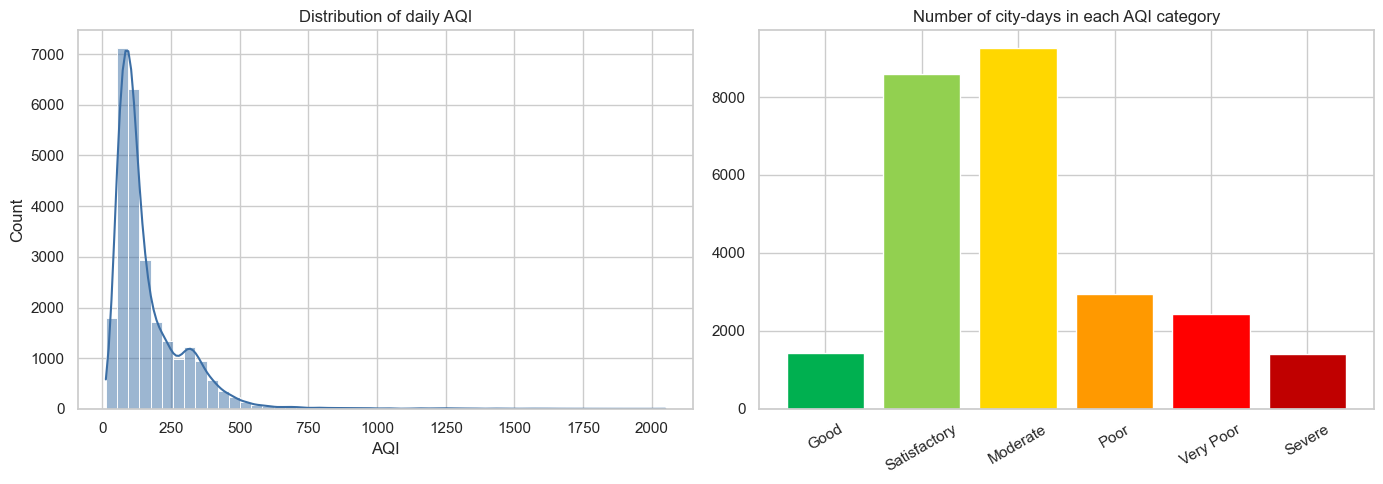

AQI_Bucket
Good             5.5 %
Satisfactory    33.0 %
Moderate        35.5 %
Poor            11.3 %
Very Poor        9.4 %
Severe           5.4 %
Name: count, dtype: object


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df.AQI, bins=50, kde=True, ax=ax[0], color="#3b6ea5")
ax[0].set_title("Distribution of daily AQI")
counts = df.AQI_Bucket.value_counts().reindex(AQI_ORDER)
ax[1].bar(counts.index, counts.values, color=[AQI_COLORS[b] for b in counts.index])
ax[1].set_title("Number of city-days in each AQI category")
ax[1].tick_params(axis="x", rotation=30)
savefig("01_aqi_distribution")
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

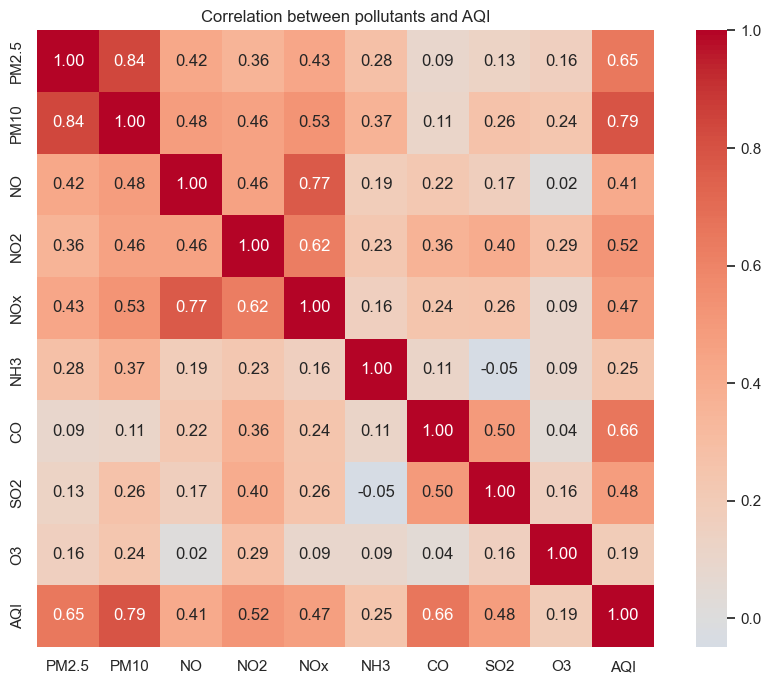

Correlation with AQI:
 PM10     0.79
CO       0.66
PM2.5    0.65
NO2      0.52
SO2      0.48
NOx      0.47
NO       0.41
NH3      0.25
O3       0.19
Name: AQI, dtype: float64


In [7]:
plt.figure(figsize=(9, 7))
corr = df[CORE + ["AQI"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between pollutants and AQI")
savefig("02_correlation_heatmap")
print("Correlation with AQI:\n", corr["AQI"].drop("AQI").sort_values(ascending=False).round(2))

## 6. Which pollutants drive AQI?
Correlation shows association; a Random Forest ranks how useful each pollutant is for *predicting* AQI.

Random Forest  R2 = 0.901   RMSE = 28.7


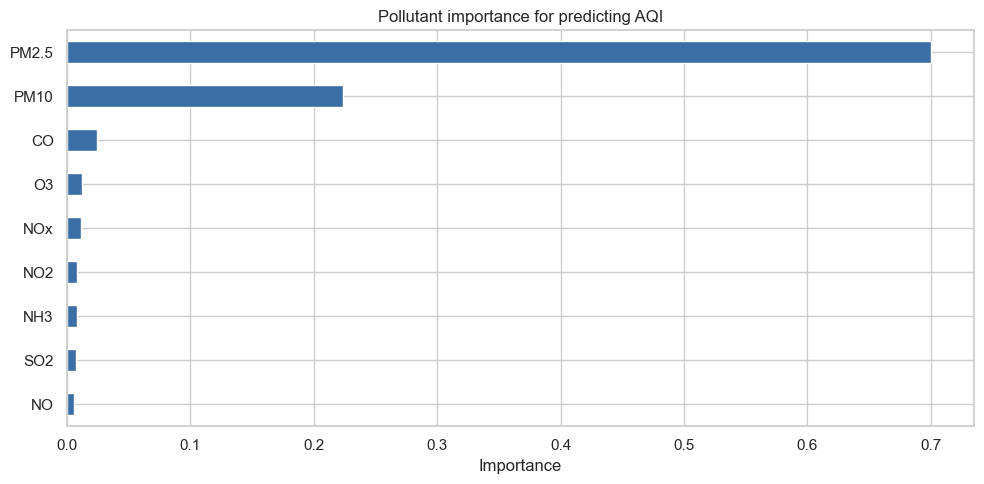

PM2.5    0.700
PM10     0.223
CO       0.024
O3       0.012
NOx      0.011
NO2      0.008
NH3      0.008
SO2      0.007
NO       0.006
dtype: float64

In [8]:
model_df = df.dropna(subset=CORE + ["AQI"])
X, y = model_df[CORE], model_df["AQI"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=200, max_depth=14, n_jobs=-1, random_state=42).fit(Xtr, ytr)
pred = rf.predict(Xte)
print(f"Random Forest  R2 = {r2_score(yte, pred):.3f}   RMSE = {np.sqrt(mean_squared_error(yte, pred)):.1f}")

imp = pd.Series(rf.feature_importances_, index=CORE).sort_values()
imp.plot(kind="barh", color="#3b6ea5", title="Pollutant importance for predicting AQI")
plt.xlabel("Importance")
savefig("03_feature_importance")
imp.sort_values(ascending=False).round(3)

## 7. Yearly, monthly and seasonal trends

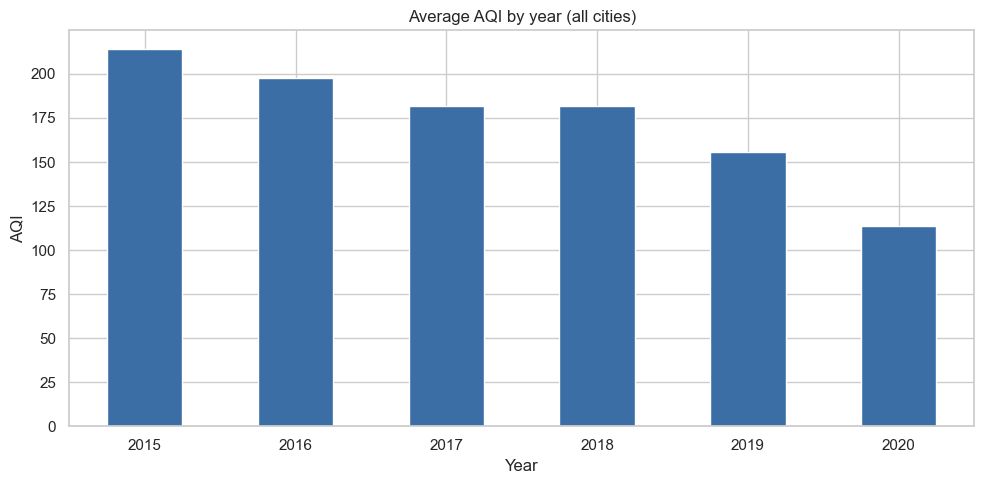

Year
2015    214.0
2016    197.5
2017    181.9
2018    181.6
2019    155.8
2020    113.6
Name: AQI, dtype: float64

In [9]:
yearly = df.groupby("Year")["AQI"].mean()
ax = yearly.plot(kind="bar", color="#3b6ea5", title="Average AQI by year (all cities)")
ax.set_ylabel("AQI"); ax.tick_params(axis="x", rotation=0)
savefig("04_yearly_aqi")
yearly.round(1)

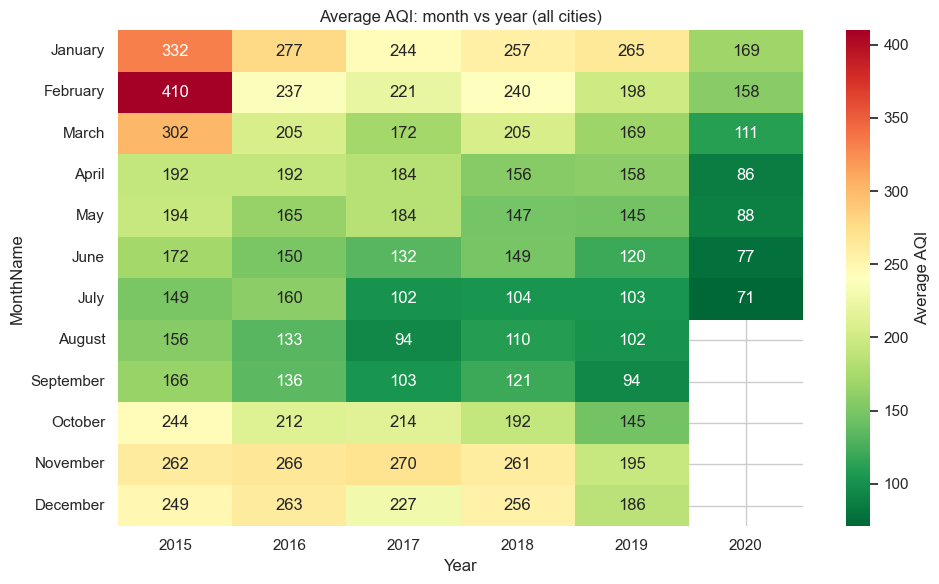

In [10]:
month_order = ["January","February","March","April","May","June","July","August",
               "September","October","November","December"]
pivot = df.pivot_table(index="MonthName", columns="Year", values="AQI", aggfunc="mean").reindex(month_order)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r", cbar_kws={"label": "Average AQI"})
plt.title("Average AQI: month vs year (all cities)")
savefig("05_month_year_heatmap")

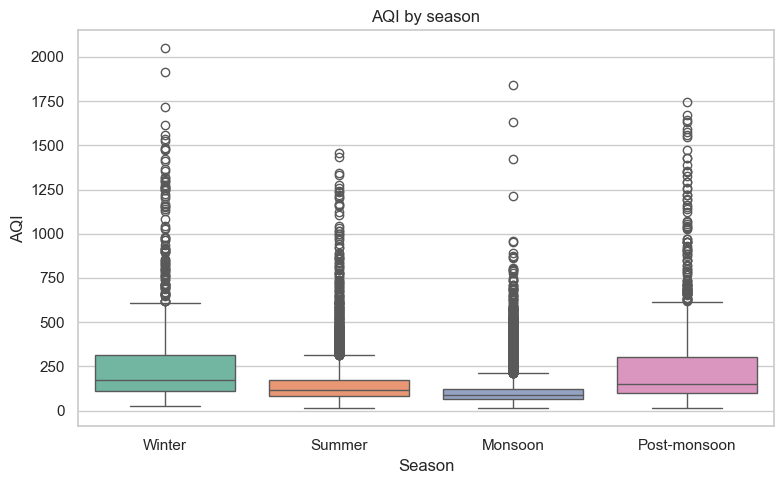

Season
Winter          221.2
Summer          148.7
Monsoon         116.1
Post-monsoon    213.9
Name: AQI, dtype: float64


In [11]:
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Season", y="AQI", order=season_order, palette="Set2")
plt.title("AQI by season")
savefig("06_seasonal_boxplot")
print(df.groupby("Season")["AQI"].mean().reindex(season_order).round(1))

## 8. City and region comparison

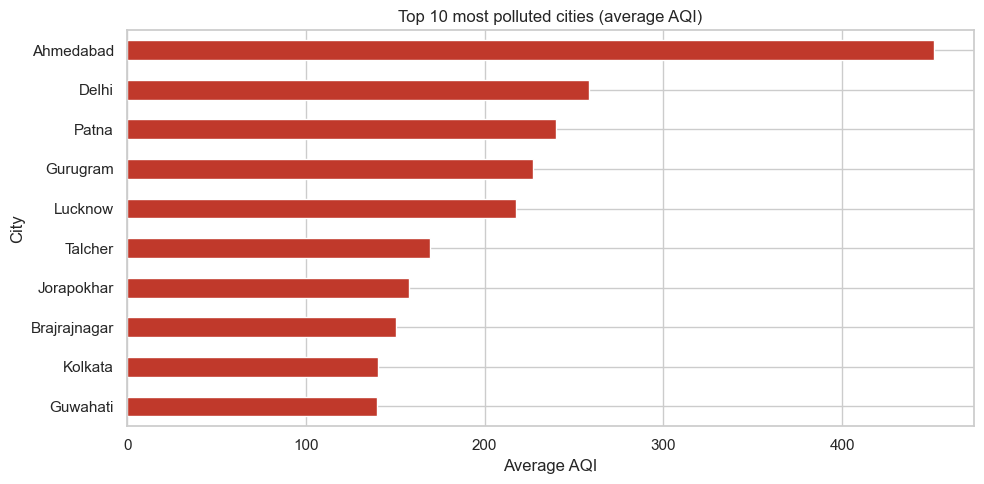

City
Ahmedabad             451.3
Delhi                 258.6
Patna                 239.7
Gurugram              227.2
Lucknow               217.7
Talcher               169.4
Jorapokhar            157.5
Brajrajnagar          150.4
Kolkata               140.1
Guwahati              139.5
Jaipur                133.3
Bhopal                131.3
Amritsar              120.1
Visakhapatnam         116.8
Chennai               115.2
Hyderabad             109.1
Mumbai                105.4
Kochi                 104.3
Chandigarh             96.2
Amaravati              94.6
Bengaluru              94.2
Ernakulam              93.4
Thiruvananthapuram     75.3
Coimbatore             73.3
Shillong               52.9
Aizawl                 34.8
Name: AQI, dtype: float64

In [12]:
city_avg = df.groupby("City")["AQI"].mean().sort_values(ascending=False)
top10 = city_avg.head(10).iloc[::-1]
top10.plot(kind="barh", color="#c0392b", title="Top 10 most polluted cities (average AQI)")
plt.xlabel("Average AQI")
savefig("07_top10_cities")
city_avg.round(1)

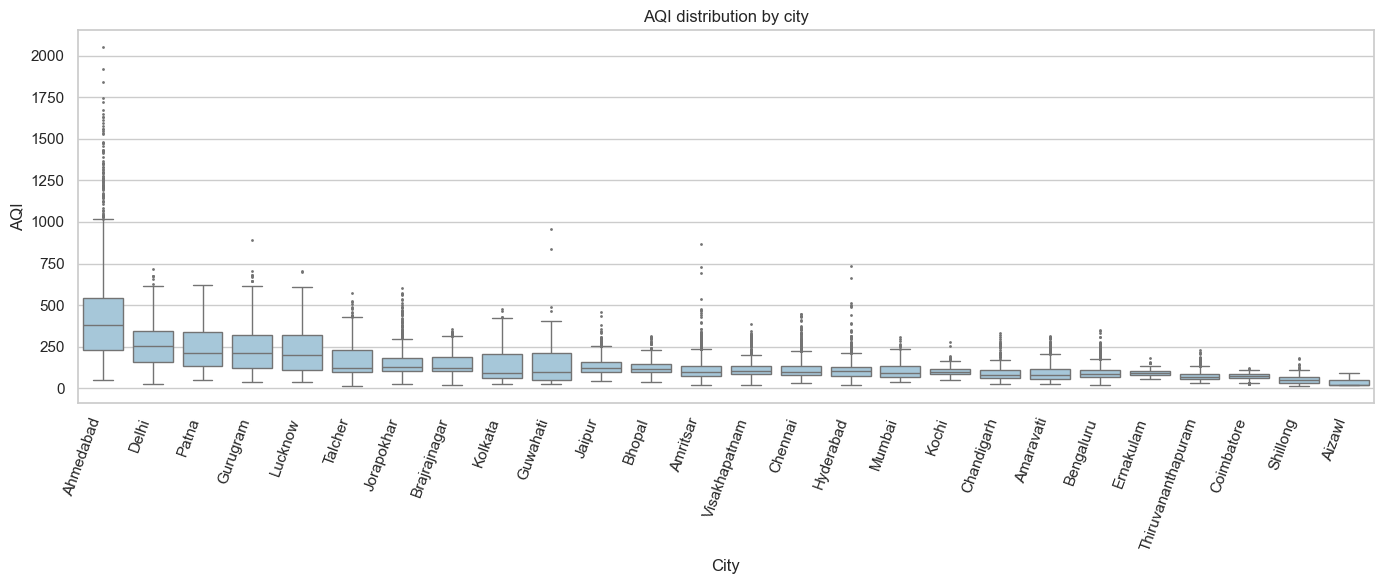

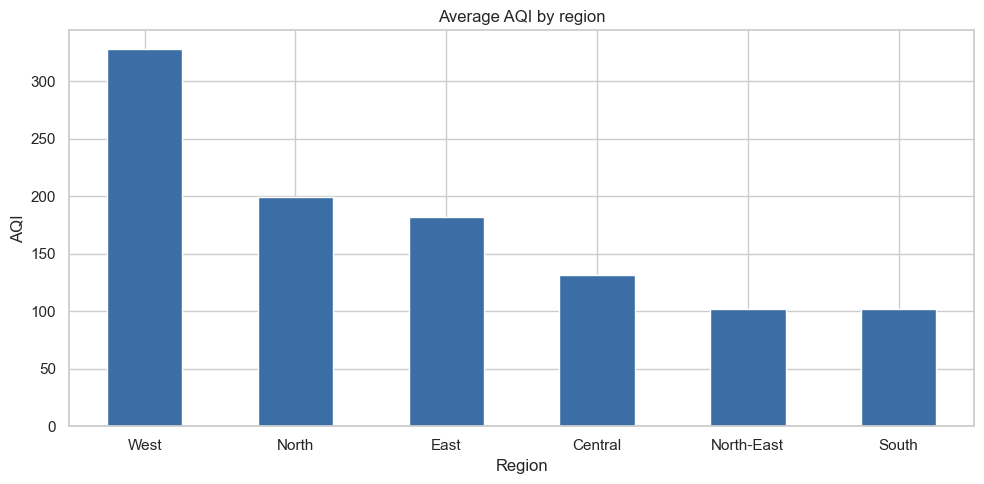

Region
West          327.7
North         199.2
East          182.0
Central       131.3
North-East    101.8
South         101.5
Name: AQI, dtype: float64

In [13]:
order = city_avg.index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="City", y="AQI", order=order, color="#9ecae1", fliersize=1)
plt.xticks(rotation=70, ha="right"); plt.title("AQI distribution by city")
savefig("08_city_boxplot")

region = df.groupby("Region")["AQI"].mean().sort_values(ascending=False)
region.plot(kind="bar", color="#3b6ea5", title="Average AQI by region")
plt.xticks(rotation=0); plt.ylabel("AQI")
savefig("09_region_aqi")
region.round(1)

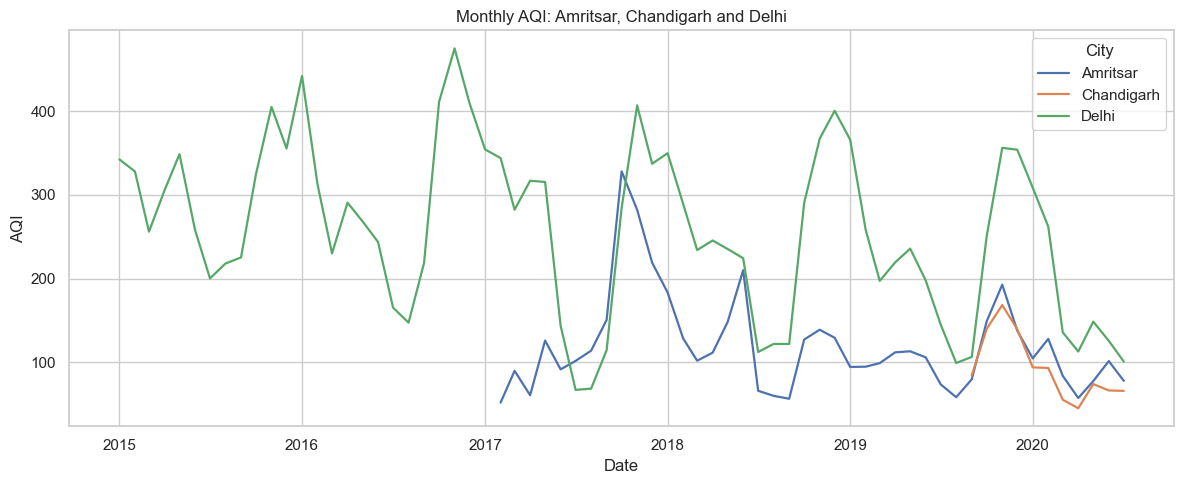

In [14]:
# Punjab / Chandigarh focus (local relevance)
local = df[df.City.isin(["Amritsar", "Chandigarh", "Delhi"])]
monthly_local = local.set_index("Date").groupby("City")["AQI"].resample("MS").mean().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_local, x="Date", y="AQI", hue="City", linewidth=1.6)
plt.title("Monthly AQI: Amritsar, Chandigarh and Delhi")
savefig("10_punjab_vs_delhi")

## 9. COVID-19 lockdown effect
The same calendar window (**25 Mar - 30 Jun**) is compared across years, so seasonality does not distort the result.
Baseline = average of 2016-2019 for each city.

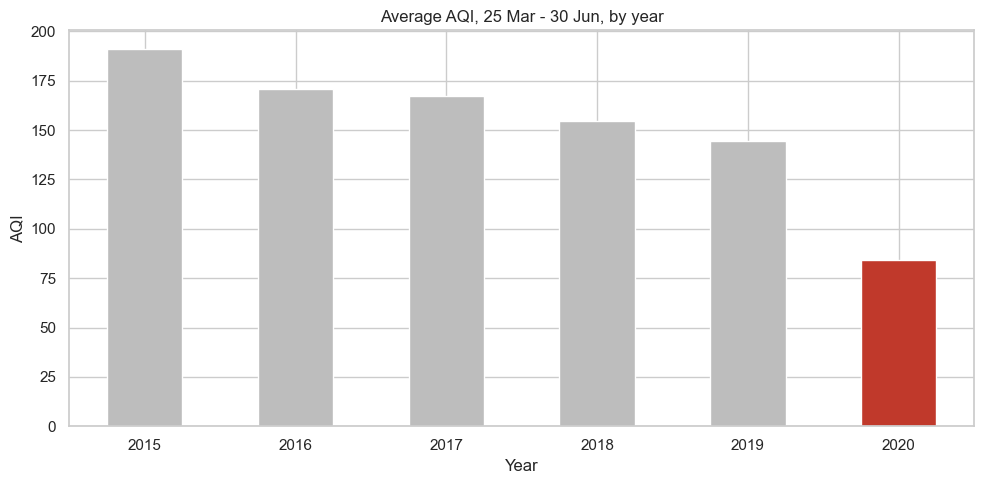

Year
2015    190.9
2016    170.7
2017    167.0
2018    154.5
2019    144.6
2020     84.4
Name: AQI, dtype: float64


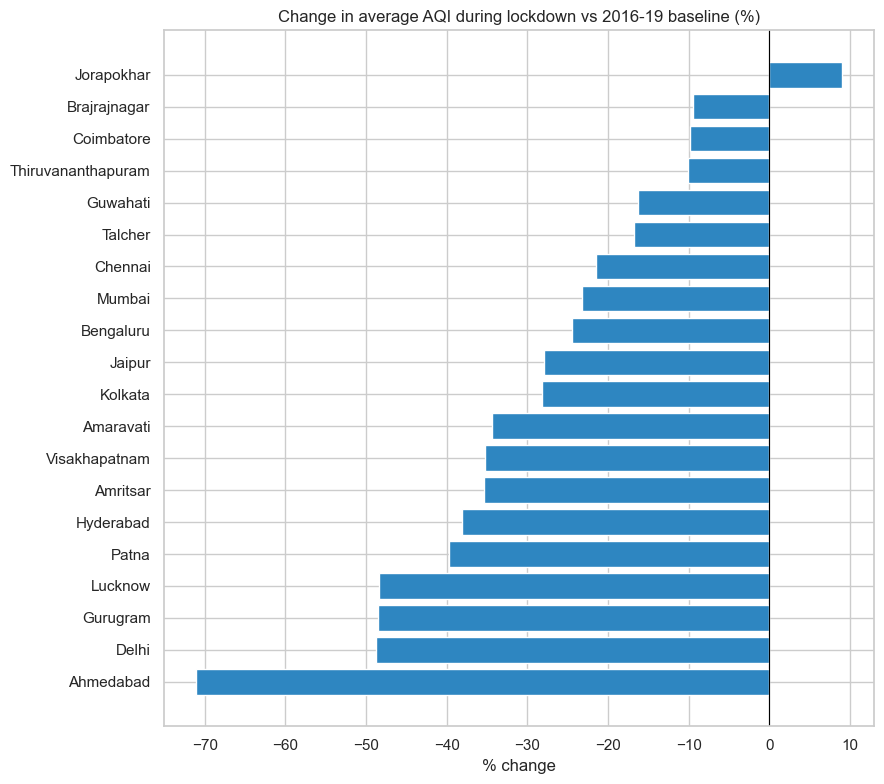

,City,Baseline_2016_19,Lockdown_2020,Pct_Change,Region
0,Ahmedabad,414.0,119.8,-71.1,West
1,Delhi,244.9,125.5,-48.8,North
2,Gurugram,245.2,126.2,-48.5,North
3,Lucknow,207.5,107.2,-48.4,North
4,Patna,195.9,118.1,-39.7,East
5,Hyderabad,103.7,64.2,-38.1,South
6,Amritsar,120.4,77.8,-35.3,North
7,Visakhapatnam,105.2,68.1,-35.2,South
8,Amaravati,79.5,52.1,-34.4,South
9,Kolkata,83.3,59.9,-28.1,East


In [15]:
win = df[df.InLockdownWindow]

by_year = win.groupby("Year")["AQI"].mean()
colors = ["#bdbdbd"] * len(by_year)
colors[list(by_year.index).index(2020)] = "#c0392b"
by_year.plot(kind="bar", color=colors, title="Average AQI, 25 Mar - 30 Jun, by year")
plt.ylabel("AQI"); plt.xticks(rotation=0)
savefig("11_lockdown_by_year")
print(by_year.round(1))

city_year = win.groupby(["City", "Year"])["AQI"].mean().unstack()
base_cols = [c for c in [2016, 2017, 2018, 2019] if c in city_year.columns]
lock = pd.DataFrame({
    "Baseline_2016_19": city_year[base_cols].mean(axis=1),
    "Lockdown_2020": city_year[2020],
}).dropna()
lock["Pct_Change"] = (lock.Lockdown_2020 - lock.Baseline_2016_19) / lock.Baseline_2016_19 * 100
lock = lock.sort_values("Pct_Change").reset_index()
lock["Region"] = lock.City.map(REGION)

plt.figure(figsize=(9, 8))
plt.barh(lock.City, lock.Pct_Change, color="#2e86c1")
plt.axvline(0, color="black", lw=0.8)
plt.title("Change in average AQI during lockdown vs 2016-19 baseline (%)")
plt.xlabel("% change")
savefig("12_lockdown_city_change")
lock.round(1)

In [16]:
# Hypothesis test: was lockdown AQI significantly lower than the same window in 2019?
from scipy import stats
a = win[(win.Year == 2019)].groupby("City")["AQI"].mean()
b = win[(win.Year == 2020)].groupby("City")["AQI"].mean()
common = a.index.intersection(b.index)
t, p_val = stats.ttest_rel(a[common], b[common])
print(f"Paired t-test across {len(common)} cities (2019 vs 2020 window): t = {t:.2f}, p = {p_val:.4g}")
print("Significant at 5% level" if p_val < 0.05 else "Not significant at 5% level")

Paired t-test across 20 cities (2019 vs 2020 window): t = 2.78, p = 0.01186
Significant at 5% level


## 10. Forecasting AQI
Monthly average AQI for one city. Three models are compared on a **12-month hold-out** set:
1. Seasonal naive (baseline: repeats last year)
2. ARIMA(2,1,2)
3. SARIMA(1,1,1)(1,1,1,12)

> The test year includes the lockdown, which no model could anticipate, so errors there are expected.

Delhi: 66 months  |  train Jan 2015-Jun 2019  |  test Jul 2019-Jun 2020

Hold-out performance:
                          RMSE  MAPE_%
Seasonal naive           55.42   30.61
ARIMA(2,1,2)             90.86   57.71
SARIMA(1,1,1)(1,1,1,12)  45.93   24.51

Best model by RMSE: SARIMA(1,1,1)(1,1,1,12)


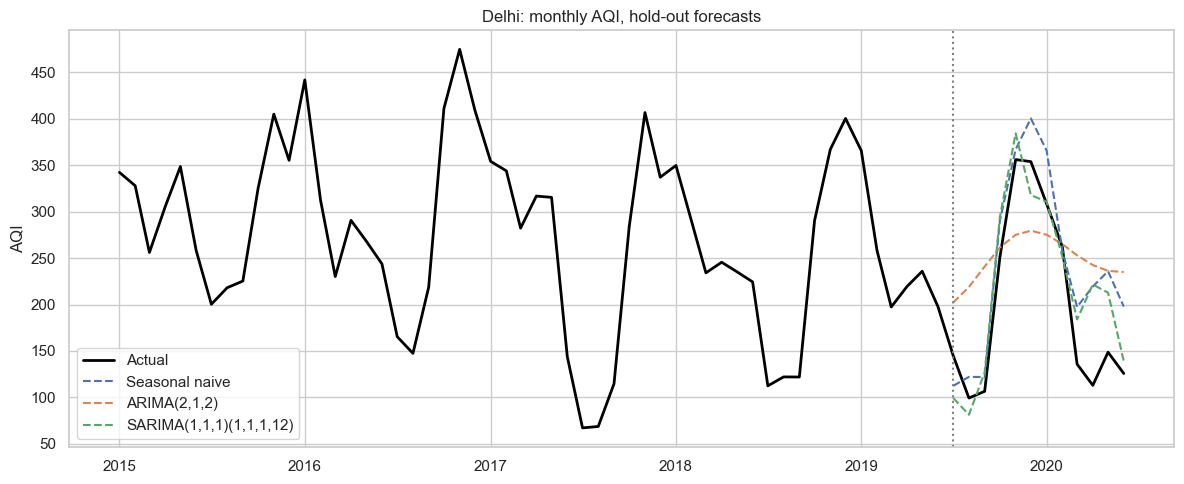

In [17]:
def monthly_series(city, min_days=15):
    g = df[df.City == city].set_index("Date")["AQI"].resample("MS").agg(["mean", "count"])
    s = g.loc[g["count"] >= min_days, "mean"]
    return s.asfreq("MS").interpolate(limit_direction="both")

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def mape(a, b): return float(np.mean(np.abs((a - b) / a)) * 100)

CITY = "Delhi"
series = monthly_series(CITY)
train, test = series.iloc[:-12], series.iloc[-12:]
print(f"{CITY}: {len(series)} months  |  train {train.index[0]:%b %Y}-{train.index[-1]:%b %Y}  |  test {test.index[0]:%b %Y}-{test.index[-1]:%b %Y}")

preds = {}
preds["Seasonal naive"] = pd.Series(train.iloc[-12:].values, index=test.index)
preds["ARIMA(2,1,2)"] = ARIMA(train, order=(2, 1, 2)).fit().forecast(12)
preds["SARIMA(1,1,1)(1,1,1,12)"] = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                                            enforce_stationarity=False, enforce_invertibility=False
                                           ).fit(disp=False).forecast(12)

scores = pd.DataFrame({k: {"RMSE": rmse(test, v), "MAPE_%": mape(test, v)} for k, v in preds.items()}).T.round(2)
best = scores["RMSE"].idxmin()
print("\nHold-out performance:"); print(scores); print("\nBest model by RMSE:", best)

plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, label="Actual", color="black", lw=2)
for k, v in preds.items():
    plt.plot(v.index, v.values, "--", label=k)
plt.axvline(test.index[0], color="grey", ls=":")
plt.title(f"{CITY}: monthly AQI, hold-out forecasts"); plt.ylabel("AQI"); plt.legend()
savefig("13_forecast_comparison")

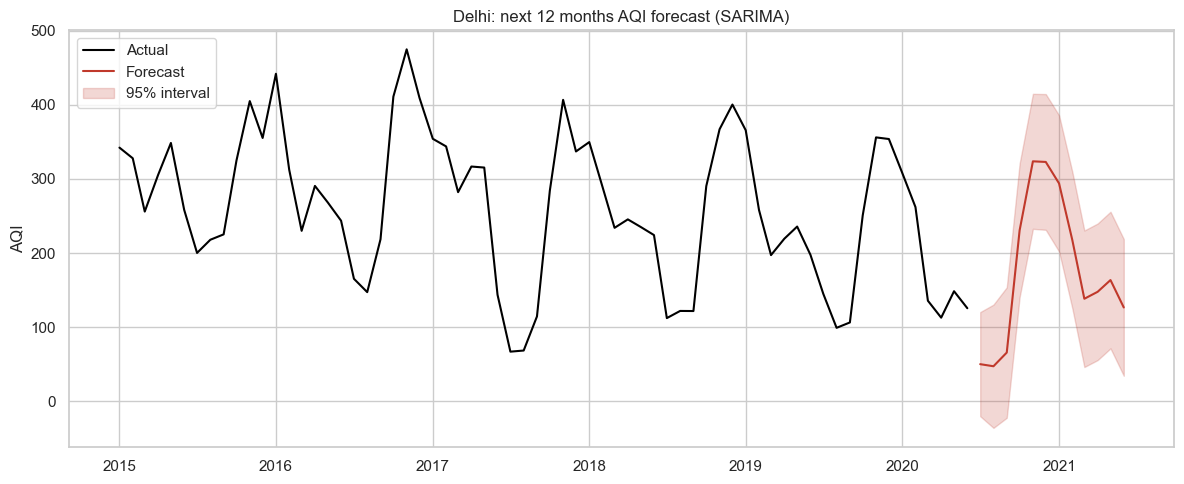

In [18]:
# Final forecast: refit on ALL data, forecast the next 12 months with a 95% interval
final = SARIMAX(series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = final.get_forecast(12)
fc_mean, fc_ci = fc.predicted_mean, fc.conf_int(alpha=0.05)

plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, color="black", label="Actual")
plt.plot(fc_mean.index, fc_mean.values, color="#c0392b", label="Forecast")
plt.fill_between(fc_mean.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], color="#c0392b", alpha=0.2, label="95% interval")
plt.title(f"{CITY}: next 12 months AQI forecast (SARIMA)"); plt.ylabel("AQI"); plt.legend()
savefig("14_future_forecast")

In [19]:
# Forecast every city with enough history -> one file for Tableau
rows, metric_rows = [], []
for city in sorted(df.City.unique()):
    s = monthly_series(city)
    if len(s) < 48:
        continue
    try:
        tr, te = s.iloc[:-12], s.iloc[-12:]
        m = SARIMAX(tr, order=(1,1,1), seasonal_order=(1,1,1,12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        p = m.forecast(12)
        metric_rows.append({"City": city, "Months": len(s), "RMSE": rmse(te, p), "MAPE_%": mape(te, p)})

        full = SARIMAX(s, order=(1,1,1), seasonal_order=(1,1,1,12),
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        f = full.get_forecast(12); ci = f.conf_int(alpha=0.05)
        for d, v in s.items():
            rows.append((city, d, "Actual", v, np.nan, np.nan))
        for d, v in p.items():
            rows.append((city, d, "Test forecast", v, np.nan, np.nan))
        for d, v, lo, hi in zip(f.predicted_mean.index, f.predicted_mean, ci.iloc[:, 0], ci.iloc[:, 1]):
            rows.append((city, d, "Future forecast", v, lo, hi))
    except Exception as e:
        print("Skipped", city, "->", e)

forecast_df = pd.DataFrame(rows, columns=["City", "Month", "Type", "AQI", "Lower_95", "Upper_95"])
forecast_df[["AQI", "Lower_95", "Upper_95"]] = forecast_df[["AQI", "Lower_95", "Upper_95"]].clip(lower=0)
forecast_metrics = pd.DataFrame(metric_rows).round(2)
print(f"Forecasts built for {forecast_metrics.City.nunique()} cities")
forecast_metrics

c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Forecasts built for 9 cities


,City,Months,RMSE,MAPE_%
0,Ahmedabad,65,3.003800e+02,1.241600e+02
1,Bengaluru,63,4.655146e+18,3.535509e+18
2,Chennai,63,3.154000e+01,3.145000e+01
3,Delhi,66,4.593000e+01,2.451000e+01
4,Gurugram,53,3.769000e+01,2.213000e+01
5,Hyderabad,63,1.848000e+01,2.040000e+01
6,Lucknow,63,5.123000e+01,3.207000e+01
7,Patna,57,4.586000e+01,2.861000e+01
8,Visakhapatnam,48,6.030000e+01,5.081000e+01


In [20]:
# Diagnose Bengaluru forecast instability

city = "Bengaluru"
s = monthly_series(city)

print("CITY:", city)
print("Total months:", len(s))
print("\nActual series statistics:")
print(s.describe())

# Train-test split
tr, te = s.iloc[:-12], s.iloc[-12:]

print("\nTraining range:", tr.index.min(), "to", tr.index.max())
print("Testing range:", te.index.min(), "to", te.index.max())

# Fit the same SARIMAX model
model = SARIMAX(
    tr,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

pred = model.forecast(12)

print("\nActual test values:")
print(te.to_string())

print("\nPredicted test values:")
print(pred.to_string())

print("\nPrediction statistics:")
print(pred.describe())

print("\nModel convergence:",
      model.mle_retvals.get("converged", "Unknown"))

print("\nRMSE:", rmse(te, pred))
print("MAPE:", mape(te, pred))

print("\nActual contains zeros:", (te == 0).any())
print("Predictions contain non-finite values:",
      not np.isfinite(pred).all())

CITY: Bengaluru
Total months: 63

Actual series statistics:
count     63.000000
mean      94.038971
std       23.867308
min       55.166667
25%       73.063978
50%       94.661290
75%      109.500000
max      160.548387
Name: mean, dtype: float64

Training range: 2015-04-01 00:00:00 to 2019-06-01 00:00:00
Testing range: 2019-07-01 00:00:00 to 2020-06-01 00:00:00

Actual test values:
Date
2019-07-01    63.741935
2019-08-01    59.354839
2019-09-01    72.966667
2019-10-01    81.129032
2019-11-01    96.200000
2019-12-01    81.774194
2020-01-01    95.322581
2020-02-01    96.482759
2020-03-01    90.741935
2020-04-01    68.533333
2020-05-01    73.161290
2020-06-01    55.166667
Freq: MS

Predicted test values:
2019-07-01   -3.231930e+15
2019-08-01   -6.931242e+15
2019-09-01   -1.486481e+16
2019-10-01   -3.187918e+16
2019-11-01   -6.836831e+16
2019-12-01   -1.466231e+17
2020-01-01   -3.144488e+17
2020-02-01   -6.743689e+17
2020-03-01   -1.446256e+18
2020-04-01   -3.101648e+18
2020-05-01   -6.65

## 11. Export Tableau-ready files

In [21]:
# 1) Main daily file
daily_cols = ["Date", "City", "Region", "Latitude", "Longitude", "Year", "MonthNum", "MonthName",
              "Season", "Period", "InLockdownWindow"] + POLL + ["AQI", "AQI_Bucket"]
df[daily_cols].round(2).to_csv(OUT_DIR / "clean_city_day.csv", index=False)

# 2) Monthly city file (small, fast in Tableau)
monthly = (df.set_index("Date").groupby("City")[POLL + ["AQI"]].resample("MS").mean()
             .dropna(subset=["AQI"]).reset_index().rename(columns={"Date": "Month"}))
monthly["Year"] = monthly.Month.dt.year
monthly["MonthName"] = monthly.Month.dt.month_name()
monthly["Region"] = monthly.City.map(REGION)
monthly.round(2).to_csv(OUT_DIR / "monthly_city.csv", index=False)

# 3) Pollutant breakdown (long format) for stacked / comparison charts
poll_long = monthly.melt(id_vars=["City", "Region", "Month", "Year", "MonthName"],
                         value_vars=CORE, var_name="Pollutant", value_name="Concentration")
poll_long.dropna().round(2).to_csv(OUT_DIR / "pollutants_long.csv", index=False)

# 4) City summary for the map and KPI cards
worst_month = (df.groupby(["City", "MonthName"])["AQI"].mean().reset_index()
                 .sort_values("AQI", ascending=False).drop_duplicates("City")
                 .set_index("City")["MonthName"])
summary = df.groupby("City").agg(
    Region=("Region", "first"), Latitude=("Latitude", "first"), Longitude=("Longitude", "first"),
    Avg_AQI=("AQI", "mean"), Median_AQI=("AQI", "median"), Max_AQI=("AQI", "max"),
    Avg_PM25=("PM2.5", "mean"), Avg_PM10=("PM10", "mean"), Days=("AQI", "size"),
    Pct_Days_Poor_or_Worse=("AQI", lambda s: (s > 200).mean() * 100),
).reset_index()
summary["Worst_Month"] = summary.City.map(worst_month)
summary["AQI_Bucket"] = pd.cut(summary.Avg_AQI, [-np.inf, 50, 100, 200, 300, 400, np.inf],
                               labels=AQI_ORDER).astype(str)
summary.round(2).sort_values("Avg_AQI", ascending=False).to_csv(OUT_DIR / "city_summary.csv", index=False)

# 5) Lockdown comparison (per city, plus per-year window averages)
lock.round(2).to_csv(OUT_DIR / "lockdown_comparison.csv", index=False)
(win.groupby(["City", "Year"])["AQI"].mean().reset_index()
    .rename(columns={"AQI": "Avg_AQI_25Mar_30Jun"}).round(2)
    .to_csv(OUT_DIR / "lockdown_window_by_year.csv", index=False))

# 6) Forecasts
forecast_df.round(2).to_csv(OUT_DIR / "forecast.csv", index=False)
forecast_metrics.to_csv(OUT_DIR / "forecast_metrics.csv", index=False)

for f in sorted(OUT_DIR.glob("*.csv")):
    print(f"{f.name:32s} {len(pd.read_csv(f)):>8,} rows")

city_summary.csv                       26 rows
clean_city_day.csv                 26,045 rows
forecast.csv                          757 rows
forecast_metrics.csv                    9 rows
lockdown_comparison.csv                20 rows
lockdown_window_by_year.csv            90 rows
monthly_city.csv                      920 rows
pollutants_long.csv                 7,719 rows


## 12. Key findings (computed from your data)

In [22]:
worst_city = city_avg.index[0]
best_city = city_avg.index[-1]
worst_season = df.groupby("Season")["AQI"].mean().idxmax()
worst_m = df.groupby("MonthName")["AQI"].mean().idxmax()
best_m = df.groupby("MonthName")["AQI"].mean().idxmin()
top_driver = imp.sort_values(ascending=False).index[0]
drop = lock.Pct_Change.median()

print(f"1. Most polluted city: {worst_city} (avg AQI {city_avg.iloc[0]:.0f}); cleanest: {best_city} ({city_avg.iloc[-1]:.0f}).")
print(f"2. Most polluted region: {region.index[0]} ({region.iloc[0]:.0f}); cleanest: {region.index[-1]} ({region.iloc[-1]:.0f}).")
print(f"3. Worst season: {worst_season}. Worst month: {worst_m}. Best month: {best_m}.")
print(f"4. Strongest AQI driver in the model: {top_driver}; PM2.5/PM10 correlations with AQI: "
      f"{corr.loc['PM2.5','AQI']:.2f} / {corr.loc['PM10','AQI']:.2f}.")
print(f"5. Lockdown: median city AQI change vs 2016-19 baseline = {drop:.1f}%  (paired t-test p = {p_val:.4g}).")
print(f"6. Share of city-days that were Poor or worse: {(df.AQI > 200).mean() * 100:.1f}%.")
print(f"7. Forecast: best hold-out model for {CITY} = {best} (RMSE {scores.loc[best, 'RMSE']:.1f}, MAPE {scores.loc[best, 'MAPE_%']:.1f}%).")

1. Most polluted city: Ahmedabad (avg AQI 451); cleanest: Aizawl (35).
2. Most polluted region: West (328); cleanest: South (101).
3. Worst season: Winter. Worst month: November. Best month: August.
4. Strongest AQI driver in the model: PM2.5; PM2.5/PM10 correlations with AQI: 0.65 / 0.79.
5. Lockdown: median city AQI change vs 2016-19 baseline = -28.0%  (paired t-test p = 0.01186).
6. Share of city-days that were Poor or worse: 26.0%.
7. Forecast: best hold-out model for Delhi = SARIMA(1,1,1)(1,1,1,12) (RMSE 45.9, MAPE 24.5%).


## 13. Limitations and future scope
- Data comes from fixed monitoring stations aggregated to city level; station coverage changes over time and cities start reporting in different years.
- Missing values were filled by short-gap interpolation; long gaps were left out rather than invented.
- The hold-out year contains the lockdown, an event no statistical forecast can anticipate, so forecast error is inflated.
- The dataset ends in mid-2020; newer data can be downloaded from CPCB and run through the same notebook.
- Meteorological variables (wind speed, temperature, humidity) and stubble-burning counts would improve both explanation and forecasting.